# INSTITUTO Univeridad Autonoma del Estado de Mexico Centro Universitario UAEM Zumpango
**Asignatura:** Investigación de Operaciones
**Práctica 3:** Algoritmo de Dijkstra (Ruta más corta)
**Integrantes:** 
- Alexis Yahir Alvarez Leon
- Ariadna Abigail Alanis Estrada, Jose Antonio Rodriguez Estudillo
**Fecha:** 15/11/26

## 1. Descripción y Planteamiento del Problema (Enfoque TI)
En una empresa de telecomunicaciones, el tráfico de red debe viajar desde un **Router Principal (Nodo 1)** hasta un **Servidor Central (Nodo 8)**. La red consta de 8 nodos (routers y switches) con diferentes retardos (pesos) en milisegundos (ms) debido a la distancia y congestión.

El objetivo es utilizar el **Algoritmo de Dijkstra** para encontrar la ruta más corta (con el menor retardo posible) desde el Nodo 1 hasta el Nodo 8, mostrando paso a paso cómo se exploran los nodos.

## 2. Definición de Datos
- **Grafo:** 8 Nodos interconectados.
- **Pesos:** Representan el retardo en milisegundos.
- **Nodo Origen:** 1
- **Nodo Destino:** 8
- **Variables:** Mantendremos un registro de `[distancia_mínima, nodo_anterior]` para cada nodo, tal como se hace manualmente.

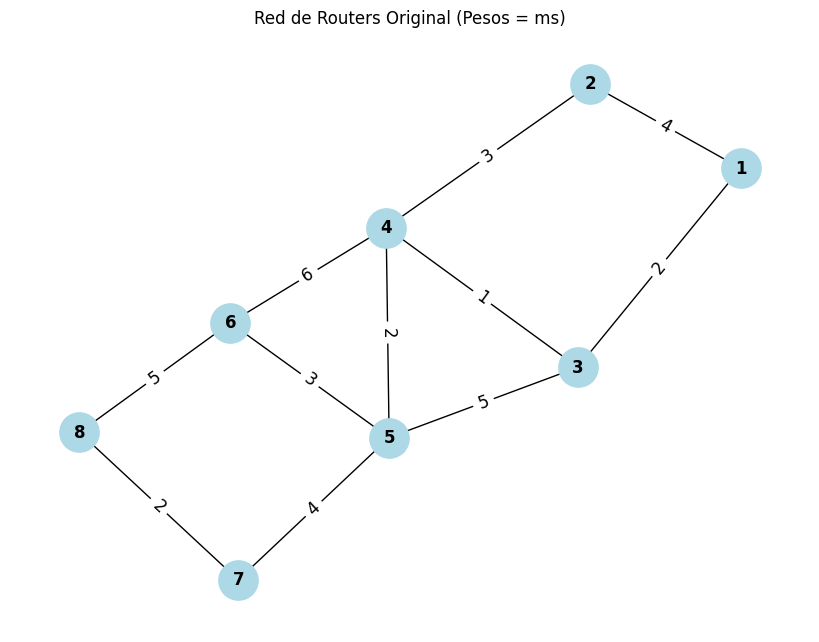

In [ ]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import heapq

# Definimos el grafo (Nodo A, Nodo B, Peso/Retardo)
aristas = [
    (1, 2, 4), (1, 3, 2), 
    (2, 4, 3), (3, 4, 1), (3, 5, 5), 
    (4, 5, 2), (4, 6, 6), 
    (5, 6, 3), (5, 7, 4), 
    (6, 8, 5), (7, 8, 2)
]

G = nx.Graph()
G.add_weighted_edges_from(aristas)
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=800, font_weight='bold')
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'), font_size=12)
plt.title("Red de Routers Original (Pesos = ms)")
plt.axis('off')
plt.show()

## 3. Desarrollo del Algoritmo Paso a Paso
A continuación, el código ejecutará Dijkstra. En cada paso, se seleccionará el nodo con la distancia más corta conocida, se actualizarán sus vecinos y **se generará una gráfica** mostrando las distancias actuales en forma de `[distancia, nodo_anterior]`.

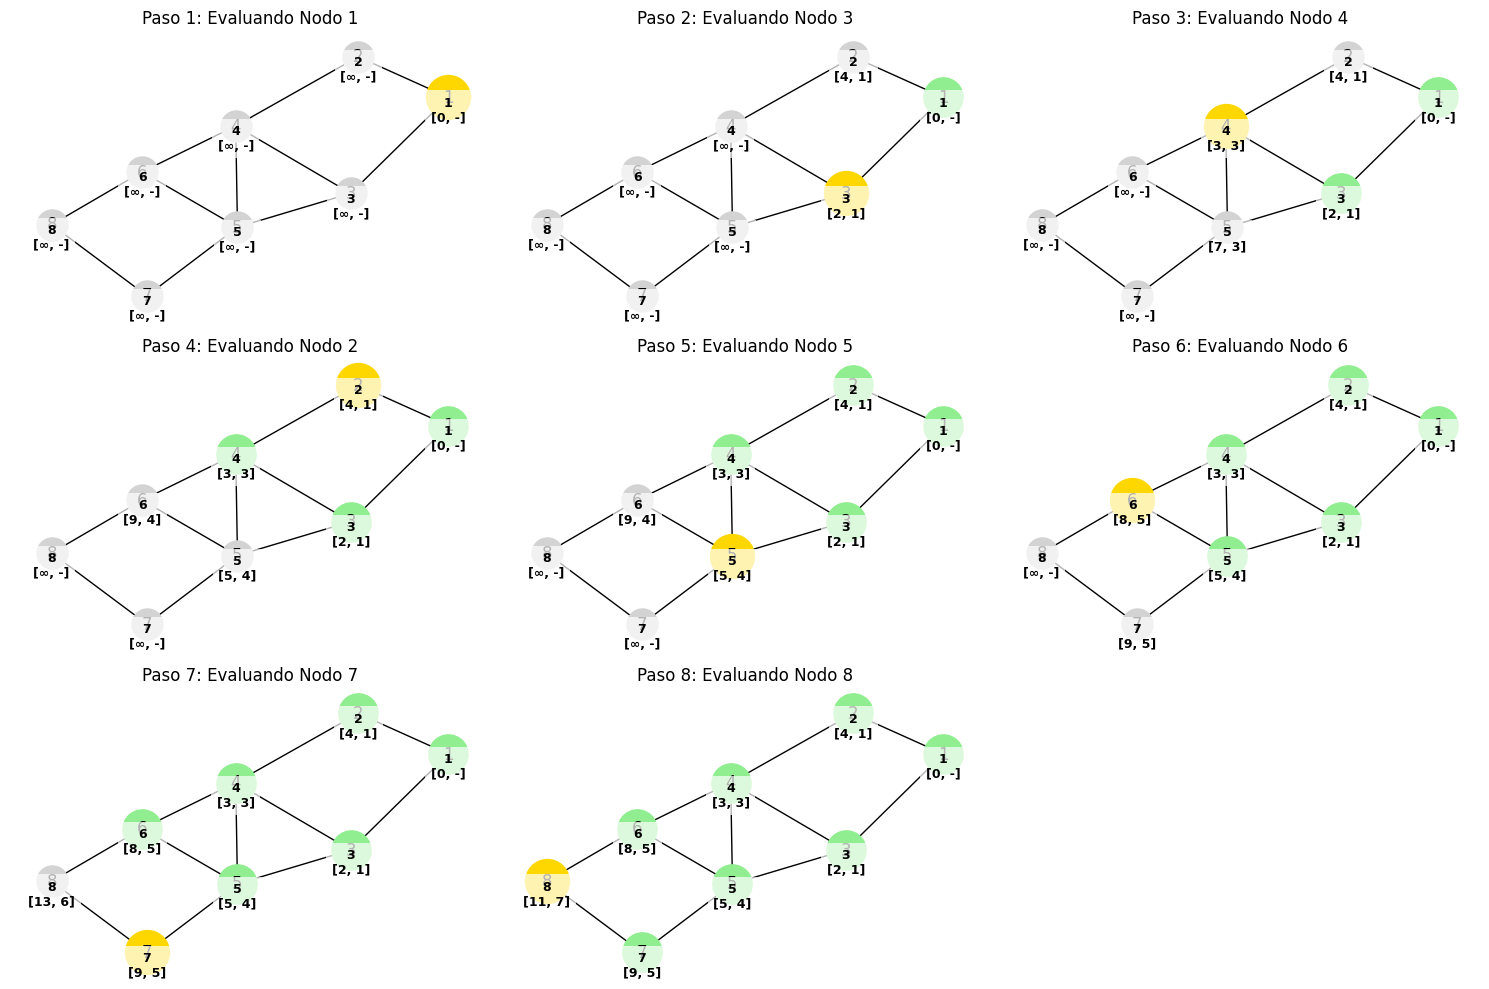


🚀 RUTA MÁS CORTA: 1 -> 3 -> 4 -> 5 -> 7 -> 8
⏱️ RETARDO TOTAL: 11 ms


In [ ]:
def dijkstra_paso_a_paso(grafo, inicio, fin):
    # Inicialización
    distancias = {nodo: float('inf') for nodo in grafo.nodes()}
    distancias[inicio] = 0
    anteriores = {nodo: None for nodo in grafo.nodes()}
    
    cola_prioridad = [(0, inicio)]
    visitados = set()
    
    fig = plt.figure(figsize=(15, 10))
    paso = 1
    
    while cola_prioridad:
        dist_actual, nodo_actual = heapq.heappop(cola_prioridad)
        
        if nodo_actual in visitados:
            continue
            
        visitados.add(nodo_actual)
        
        # --- GRAFICAR EL PASO ACTUAL ---
        plt.subplot(3, 3, paso)
        nx.draw(grafo, pos, with_labels=True, node_color='lightgray', node_size=500)
        
        # Crear etiquetas con el formato [distancia, anterior]
        etiquetas = {}
        for n in grafo.nodes():
            d = distancias[n] if distancias[n] != float('inf') else '∞'
            a = anteriores[n] if anteriores[n] is not None else '-'
            etiquetas[n] = f"{n}\n[{d}, {a}]"
            
        # Resaltar nodo actual y visitados
        nx.draw_networkx_nodes(grafo, pos, nodelist=list(visitados), node_color='lightgreen', node_size=800)
        nx.draw_networkx_nodes(grafo, pos, nodelist=[nodo_actual], node_color='gold', node_size=1000)
        
        # Dibujar etiquetas
        for n, (x, y) in pos.items():
            plt.text(x, y - 0.15, etiquetas[n], ha='center', fontsize=9, fontweight='bold', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
            
        plt.title(f"Paso {paso}: Evaluando Nodo {nodo_actual}")
        paso += 1
        
        if nodo_actual == fin:
            break
            
        # Actualizar vecinos
        for vecino in grafo.neighbors(nodo_actual):
            peso = grafo[nodo_actual][vecino]['weight']
            nueva_dist = dist_actual + peso
            
            if nueva_dist < distancias[vecino]:
                distancias[vecino] = nueva_dist
                anteriores[vecino] = nodo_actual
                heapq.heappush(cola_prioridad, (nueva_dist, vecino))
                
    plt.tight_layout()
    plt.show()
    
    # Reconstruir la ruta
    ruta = []
    actual = fin
    while actual is not None:
        ruta.insert(0, actual)
        actual = anteriores[actual]
        
    return ruta, distancias[fin]

# Ejecutar
ruta_optima, distancia_total = dijkstra_paso_a_paso(G, 1, 8)
print(f"\n RUTA MÁS CORTA: {' -> '.join(map(str, ruta_optima))}")
print(f" RETARDO TOTAL: {distancia_total} ms")

## 4. Solución Final
Una vez calculadas todas las distancias, mostramos gráficamente la ruta más corta resaltada en color azul.

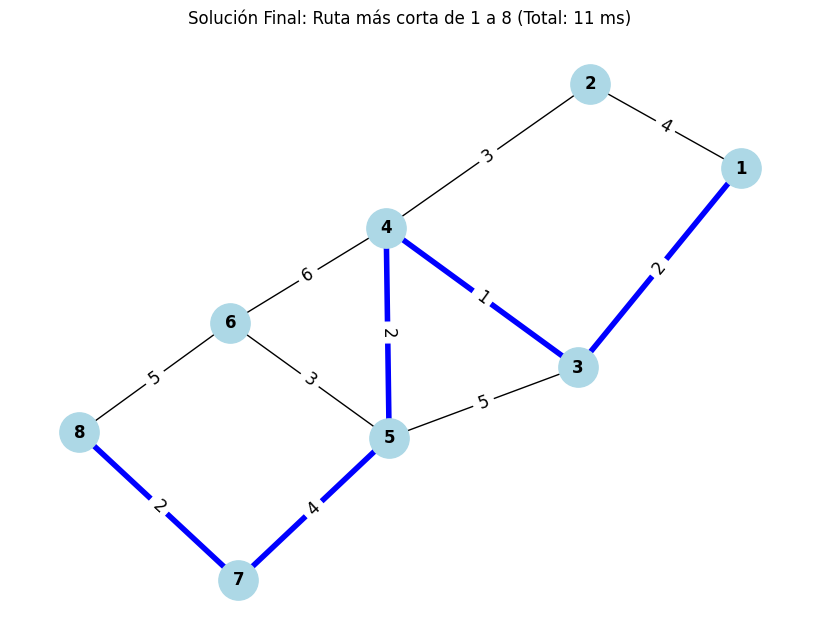

In [3]:
plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=800, font_weight='bold')

# Crear lista de aristas de la ruta óptima
aristas_ruta = [(ruta_optima[i], ruta_optima[i+1]) for i in range(len(ruta_optima)-1)]

# Resaltar ruta
nx.draw_networkx_edges(G, pos, edgelist=aristas_ruta, edge_color='blue', width=4)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'), font_size=12)

plt.title(f"Solución Final: Ruta más corta de 1 a 8 (Total: {distancia_total} ms)")
plt.axis('off')
plt.show()

## 5. Interpretación de Resultados
El Algoritmo de Dijkstra determinó que la ruta más eficiente para enviar los paquetes desde el Router 1 hasta el Servidor 8 es **1 -> 3 -> 4 -> 5 -> 7 -> 8**, con un retardo total de **11 ms**. 
Al comparar todas las alternativas, esta ruta minimiza el tiempo de transmisión. Los nodos que no pertenecen a la ruta todavía tienen holgura para recibir tráfico sin afectar esta conexión principal.

## 6. Conclusiones
**Ariadna Abigail**:
La forma en que se actualizan las distancias en cada gráfica muestra claramente cómo viajan los datos. Es muy útil para entender cómo se elige el camino más rápido en una red.

**Jose Antonio**:
Este algoritmo es la base de los protocolos de enrutamiento. Ver cómo descarta los caminos largos y se queda con el más corto demuestra su utilidad real en las telecomunicaciones.


